# Employee Resignation Prediction

## Progress Review I — Viva Evidence Notebook

**Student ID:** IT25100385  
**Contribution:** Categorical Encoding / One-Hot Encoding

### Purpose

This notebook provides individual viva evidence for categorical encoding in the Employee Resignation Prediction project. It identifies the approved nominal predictors and will demonstrate leakage-safe one-hot encoding with the project's frozen development folds.

### Important boundaries

- Only the official 80,000-row development partition will be used.
- The encoder vocabulary will be learned from development-training folds only.
- The 20,000-row formal holdout will not be inspected or transformed.
- No universal encoded dataset will be created because categorical representation is model-specific.

In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import Markdown, display
from sklearn.preprocessing import OneHotEncoder

# Keep tables and figures clear and readable for the viva.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

In [2]:
# Locate the repository root whether Jupyter starts there or inside notebooks/.
current_path = Path.cwd().resolve()
project_root = next(
    (
        candidate
        for candidate in [current_path, *current_path.parents]
        if (candidate / "data" / "raw").is_dir()
        and (candidate / "configs" / "feature_contract.yaml").is_file()
    ),
    None,
)
assert project_root is not None, "Could not locate the project root."

raw_data_path = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)
split_registry_path = project_root / "data" / "processed" / "split_registry.csv"
feature_contract_path = project_root / "configs" / "feature_contract.yaml"

for required_path in [raw_data_path, split_registry_path, feature_contract_path]:
    assert required_path.is_file(), f"Required project file not found: {required_path}"

def calculate_canonical_sha256(file_path: Path) -> str:
    """Calculate SHA-256 after normalizing CRLF line endings to canonical LF."""
    file_bytes = file_path.read_bytes()
    canonical_bytes = file_bytes.replace(b"\r\n", b"\n")
    return hashlib.sha256(canonical_bytes).hexdigest()

with feature_contract_path.open("r", encoding="utf-8") as file_handle:
    feature_contract = yaml.safe_load(file_handle)

assert feature_contract["contract"]["status"] == "frozen"
assert calculate_canonical_sha256(raw_data_path) == feature_contract["dataset"]["sha256"]
assert calculate_canonical_sha256(split_registry_path) == feature_contract["split_registry"]["sha256"]

raw_df = pd.read_csv(raw_data_path)
split_registry = pd.read_csv(split_registry_path, dtype={"cv_fold": "Int64"})

expected_raw_shape = (
    feature_contract["dataset"]["expected_rows"],
    feature_contract["dataset"]["expected_columns"],
)
assert raw_df.shape == expected_raw_shape
assert split_registry.columns.tolist() == ["Employee_ID", "partition", "cv_fold"]
assert len(split_registry) == expected_raw_shape[0]
assert raw_df["Employee_ID"].is_unique and split_registry["Employee_ID"].is_unique

print("Project root:", project_root)
print("Raw dataset shape:", raw_df.shape)
print("Split registry shape:", split_registry.shape)
print("Feature contract status:", feature_contract["contract"]["status"])
print("Canonical LF-normalized data checksums: VERIFIED")
print("Checksum verification is line-ending normalized for cross-platform reproducibility.")

Project root: C:\Users\HP\Desktop\SLIIT\2Y1S\AIML\Project
Raw dataset shape: (100000, 20)
Split registry shape: (100000, 3)
Feature contract status: frozen
Canonical LF-normalized data checksums: VERIFIED
Checksum verification is line-ending normalized for cross-platform reproducibility.


In [3]:
# Derive the approved categorical predictors from the frozen feature contract.
categorical_columns = [
    feature["name"]
    for feature in feature_contract["categorical_features"]
]
target_column = feature_contract["target"]["column"]
excluded_from_encoding = ["Employee_ID", "Hire_Date", target_column]

assert categorical_columns == [
    "Department",
    "Gender",
    "Job_Title",
    "Education_Level",
]
assert not set(excluded_from_encoding).intersection(categorical_columns)

# Select development identifiers and frozen folds before joining feature values.
development_registry = split_registry.loc[
    split_registry["partition"].eq("development"),
    ["Employee_ID", "partition", "cv_fold"],
].copy()
formal_holdout_ids = set(
    split_registry.loc[
        split_registry["partition"].eq("holdout"),
        "Employee_ID",
    ]
)

development_df = development_registry.merge(
    raw_df,
    on="Employee_ID",
    how="inner",
    validate="one_to_one",
)

expected_development_rows = feature_contract["split_registry"]["development_rows"]
assert len(development_df) == expected_development_rows == 80_000
assert development_df["partition"].eq("development").all()
assert development_df["cv_fold"].notna().all()
assert set(development_df["Employee_ID"]).isdisjoint(formal_holdout_ids)

X_categorical = development_df[categorical_columns].copy()
y_development = development_df[target_column].astype(int).copy()

assert X_categorical.columns.tolist() == categorical_columns
assert not set(excluded_from_encoding).intersection(X_categorical.columns)
assert len(X_categorical) == len(y_development) == 80_000

print(f"Development records selected: {len(development_df):,}")
print(f"Approved categorical predictors ({len(categorical_columns)}): {categorical_columns}")
print("Excluded from categorical encoding:", excluded_from_encoding)
print("Formal holdout records used for analysis: 0")
display(X_categorical.head())

Development records selected: 80,000
Approved categorical predictors (4): ['Department', 'Gender', 'Job_Title', 'Education_Level']
Excluded from categorical encoding: ['Employee_ID', 'Hire_Date', 'Resigned']
Formal holdout records used for analysis: 0


,Department,Gender,Job_Title,Education_Level
0,IT,Male,Specialist,High School
1,Finance,Male,Developer,High School
2,Customer Support,Female,Analyst,Bachelor
3,Engineering,Female,Analyst,Bachelor
4,IT,Male,Technician,Bachelor


In [4]:
# Calculate category and missing-value evidence from development data only.
contract_categories = {
    feature["name"]: feature["expected_categories"]
    for feature in feature_contract["categorical_features"]
}

category_audit_records = []
category_frequency_parts = []
actual_category_counts = {}

for column in categorical_columns:
    observed_categories = sorted(
        X_categorical[column].dropna().unique().tolist()
    )
    observed_count = len(observed_categories)
    missing_count = int(X_categorical[column].isna().sum())
    actual_category_counts[column] = observed_count

    category_audit_records.append(
        {
            "categorical_feature": column,
            "observed_category_count": observed_count,
            "missing_value_count": missing_count,
            "observed_categories": observed_categories,
            "matches_frozen_contract": (
                set(observed_categories) == set(contract_categories[column])
            ),
        }
    )

    frequency_table = (
        X_categorical[column]
        .value_counts(dropna=False)
        .rename_axis("category")
        .reset_index(name="development_rows")
    )
    frequency_table.insert(0, "categorical_feature", column)
    frequency_table["percentage"] = (
        frequency_table["development_rows"] / len(X_categorical) * 100
    )
    category_frequency_parts.append(frequency_table)

category_audit = pd.DataFrame(category_audit_records)
category_frequency_table = pd.concat(
    category_frequency_parts,
    ignore_index=True,
)
total_observed_categories = sum(actual_category_counts.values())

assert category_audit["matches_frozen_contract"].all()

print("Development-only categorical audit:")
display(category_audit)
print(f"Total observed categories across the four predictors: {total_observed_categories}")
print("Development-only category frequencies:")
display(category_frequency_table.style.format({"percentage": "{:.2f}%"}))

Development-only categorical audit:


,categorical_feature,observed_category_count,missing_value_count,observed_categories,matches_frozen_contract
0,Department,9,0,"[Customer Support, Engineering, Finance, HR, IT, Legal, Marketing, Operations, Sales]",True
1,Gender,3,0,"[Female, Male, Other]",True
2,Job_Title,7,0,"[Analyst, Consultant, Developer, Engineer, Manager, Specialist, Technician]",True
3,Education_Level,4,0,"[Bachelor, High School, Master, PhD]",True


Total observed categories across the four predictors: 23
Development-only category frequencies:


,categorical_feature,category,development_rows,percentage
0,Department,Operations,9037,11.30%
1,Department,Marketing,8969,11.21%
2,Department,Sales,8936,11.17%
3,Department,Customer Support,8927,11.16%
4,Department,Finance,8895,11.12%
5,Department,IT,8892,11.12%
6,Department,Legal,8855,11.07%
7,Department,HR,8749,10.94%
8,Department,Engineering,8740,10.93%
9,Gender,Male,38537,48.17%


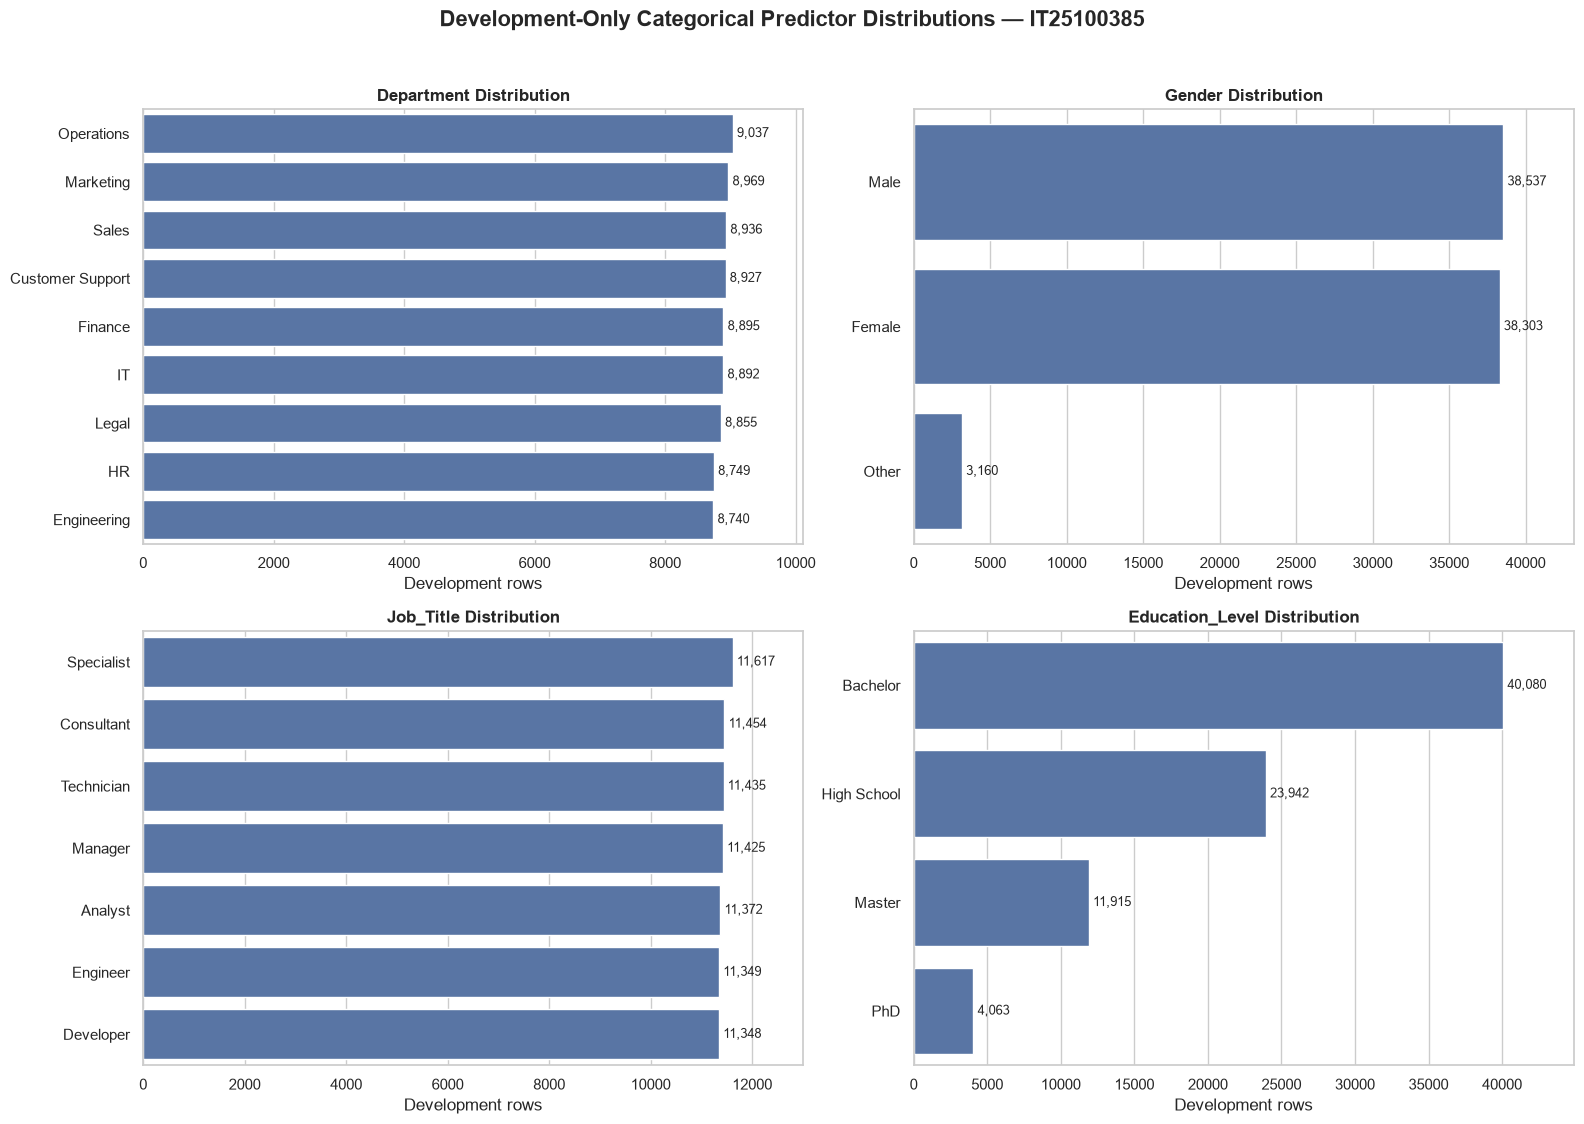

In [5]:
# Visualize development-only category frequencies for all four predictors.
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    category_order = X_categorical[column].value_counts().index
    sns.countplot(
        data=X_categorical,
        y=column,
        order=category_order,
        color="#4C72B0",
        ax=ax,
    )
    ax.set_title(f"{column} Distribution", fontweight="bold")
    ax.set_xlabel("Development rows")
    ax.set_ylabel("")
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)
    ax.margins(x=0.12)

fig.suptitle(
    "Development-Only Categorical Predictor Distributions — IT25100385",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
plt.show()

In [6]:
# Use one existing frozen fold for validation and the other four for training.
available_folds = sorted(
    development_df["cv_fold"].dropna().astype(int).unique().tolist()
)
fold_counts = (
    development_df["cv_fold"]
    .astype(int)
    .value_counts()
    .sort_index()
)

assert available_folds == [1, 2, 3, 4, 5]
assert fold_counts.tolist() == [16_000] * 5

validation_fold = 1
validation_mask = development_df["cv_fold"].astype(int).eq(validation_fold)

training_df = development_df.loc[~validation_mask].copy()
validation_df = development_df.loc[validation_mask].copy()

X_train_categorical = training_df[categorical_columns].copy()
X_valid_categorical = validation_df[categorical_columns].copy()

training_ids = set(training_df["Employee_ID"])
validation_ids = set(validation_df["Employee_ID"])
development_ids = set(development_df["Employee_ID"])

assert len(training_df) == 64_000
assert len(validation_df) == 16_000
assert training_ids.isdisjoint(validation_ids)
assert training_ids.union(validation_ids) == development_ids
assert training_ids.isdisjoint(formal_holdout_ids)
assert validation_ids.isdisjoint(formal_holdout_ids)
assert X_train_categorical.columns.tolist() == categorical_columns
assert X_valid_categorical.columns.tolist() == categorical_columns

print("Frozen development-fold counts:")
display(fold_counts.rename("development_rows").to_frame())
print(f"Validation fold: {validation_fold}")
print(f"Training rows (four folds): {len(training_df):,}")
print(f"Validation rows (one fold): {len(validation_df):,}")
print("Training categorical shape:", X_train_categorical.shape)
print("Validation categorical shape:", X_valid_categorical.shape)
print("Formal holdout rows used: 0")

Frozen development-fold counts:


,development_rows
cv_fold,
1,16000
2,16000
3,16000
4,16000
5,16000


Validation fold: 1
Training rows (four folds): 64,000
Validation rows (one fold): 16,000
Training categorical shape: (64000, 4)
Validation categorical shape: (16000, 4)
Formal holdout rows used: 0


In [7]:
# Initialize the encoder only; fitting is performed on training data in Cell 9.
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
)

encoder_configuration = pd.DataFrame(
    {
        "setting": ["sparse_output", "handle_unknown"],
        "value": [False, "ignore"],
        "purpose": [
            "Return a dense array that is easy to inspect during the viva.",
            (
                "Allow a category not learned from training data to be transformed "
                "without an error; its one-hot values for that source feature are all zero."
            ),
        ],
    }
)

print("OneHotEncoder initialized but not yet fitted.")
display(encoder_configuration)

OneHotEncoder initialized but not yet fitted.


,setting,value,purpose
0,sparse_output,False,Return a dense array that is easy to inspect during the viva.
1,handle_unknown,ignore,Allow a category not learned from training data to be transformed without an error; its one-hot values for that sour...


In [8]:
# Learn the categorical vocabulary from training folds only.
X_train_encoded = encoder.fit_transform(X_train_categorical)
encoder_fit_scope = "training_only"
encoder_fit_row_count = len(X_train_categorical)

learned_vocabulary_records = []
for column, learned_categories in zip(categorical_columns, encoder.categories_):
    training_categories = set(X_train_categorical[column].dropna().unique())
    assert set(learned_categories) == training_categories

    learned_vocabulary_records.append(
        {
            "source_feature": column,
            "learned_category_count": len(learned_categories),
            "training_categories": learned_categories.tolist(),
        }
    )

learned_category_vocabulary = pd.DataFrame(learned_vocabulary_records)
training_encoded_width = X_train_encoded.shape[1]

assert encoder_fit_scope == "training_only"
assert encoder_fit_row_count == 64_000
assert X_train_encoded.shape[0] == 64_000
assert training_encoded_width == sum(
    len(categories) for categories in encoder.categories_
)

print("Encoder fitted with fit_transform() on training categorical data only.")
print(f"Training rows used to learn the vocabulary: {encoder_fit_row_count:,}")
print(f"Encoded training width derived from learned categories: {training_encoded_width}")
display(learned_category_vocabulary)

Encoder fitted with fit_transform() on training categorical data only.
Training rows used to learn the vocabulary: 64,000
Encoded training width derived from learned categories: 23


,source_feature,learned_category_count,training_categories
0,Department,9,"[Customer Support, Engineering, Finance, HR, IT, Legal, Marketing, Operations, Sales]"
1,Gender,3,"[Female, Male, Other]"
2,Job_Title,7,"[Analyst, Consultant, Developer, Engineer, Manager, Specialist, Technician]"
3,Education_Level,4,"[Bachelor, High School, Master, PhD]"


In [9]:
# Apply the training-fitted encoder to validation data without refitting it.
X_valid_encoded = encoder.transform(X_valid_categorical)
validation_transform_scope = "transform_only"
validation_transform_row_count = len(X_valid_categorical)

assert encoder_fit_scope == "training_only"
assert validation_transform_scope == "transform_only"
assert validation_transform_row_count == 16_000
assert X_valid_encoded.shape[0] == 16_000
assert X_valid_encoded.shape[1] == X_train_encoded.shape[1]
assert validation_ids.isdisjoint(formal_holdout_ids)

validation_sample = pd.DataFrame(
    X_valid_encoded[:5],
    columns=encoder.get_feature_names_out(categorical_columns),
    index=validation_df["Employee_ID"].head(5).to_numpy(),
)
validation_sample.index.name = "Employee_ID (traceability only)"

print("Validation categorical data transformed with transform() only.")
print(f"Validation rows transformed: {validation_transform_row_count:,}")
print("The encoder was not fitted or refitted on validation data.")
display(validation_sample)

Validation categorical data transformed with transform() only.
Validation rows transformed: 16,000
The encoder was not fitted or refitted on validation data.


,Department_Customer Support,Department_Engineering,Department_Finance,Department_HR,Department_IT,Department_Legal,Department_Marketing,Department_Operations,Department_Sales,Gender_Female,Gender_Male,Gender_Other,Job_Title_Analyst,Job_Title_Consultant,Job_Title_Developer,Job_Title_Engineer,Job_Title_Manager,Job_Title_Specialist,Job_Title_Technician,Education_Level_Bachelor,Education_Level_High School,Education_Level_Master,Education_Level_PhD
Employee_ID (traceability only),,,,,,,,,,,,,,,,,,,,,,,
24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
26,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
36,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
41,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
58,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [10]:
# Derive encoded dimensions and names from the fitted encoder.
encoded_feature_names = encoder.get_feature_names_out(categorical_columns)
encoded_feature_count = len(encoded_feature_names)
learned_category_total = sum(len(categories) for categories in encoder.categories_)

assert X_train_encoded.shape == (len(X_train_categorical), encoded_feature_count)
assert X_valid_encoded.shape == (len(X_valid_categorical), encoded_feature_count)
assert encoded_feature_count == learned_category_total

feature_mapping_records = []
feature_offset = 0

for source_feature, learned_categories in zip(
    categorical_columns,
    encoder.categories_,
):
    generated_names = encoded_feature_names[
        feature_offset : feature_offset + len(learned_categories)
    ]

    for category, encoded_name in zip(learned_categories, generated_names):
        feature_mapping_records.append(
            {
                "source_feature": source_feature,
                "category": category,
                "encoded_feature_name": encoded_name,
            }
        )

    feature_offset += len(learned_categories)

encoded_feature_mapping = pd.DataFrame(feature_mapping_records)
assert len(encoded_feature_mapping) == encoded_feature_count

encoded_shape_summary = pd.DataFrame(
    {
        "dataset": ["Training folds", "Validation fold"],
        "input_rows": [len(X_train_categorical), len(X_valid_categorical)],
        "original_categorical_columns": [
            len(categorical_columns),
            len(categorical_columns),
        ],
        "encoded_columns": [
            X_train_encoded.shape[1],
            X_valid_encoded.shape[1],
        ],
    }
)

print("Encoded shape summary:")
display(encoded_shape_summary)
print(f"Actual encoded feature count: {encoded_feature_count}")
print(
    "Actual encoded feature count equals the category total observed across "
    f"the full development partition: {encoded_feature_count == total_observed_categories}"
)
print(f"Actual encoded feature count equals 23: {encoded_feature_count == 23}")
print("Encoded feature names and their original categorical variables:")
display(encoded_feature_mapping)

Encoded shape summary:


,dataset,input_rows,original_categorical_columns,encoded_columns
0,Training folds,64000,4,23
1,Validation fold,16000,4,23


Actual encoded feature count: 23
Actual encoded feature count equals the category total observed across the full development partition: True
Actual encoded feature count equals 23: True
Encoded feature names and their original categorical variables:


,source_feature,category,encoded_feature_name
0,Department,Customer Support,Department_Customer Support
1,Department,Engineering,Department_Engineering
2,Department,Finance,Department_Finance
3,Department,HR,Department_HR
4,Department,IT,Department_IT
5,Department,Legal,Department_Legal
6,Department,Marketing,Department_Marketing
7,Department,Operations,Department_Operations
8,Department,Sales,Department_Sales
9,Gender,Female,Gender_Female


## Encoding Methodology

### Why one-hot encoding is suitable

The approved categorical predictors are nominal: their category names do not have a meaningful numerical order. One-hot encoding represents each learned category with its own binary feature, allowing a model to use category membership without imposing an artificial ranking. `handle_unknown="ignore"` allows a later validation record containing an unseen category to be transformed without causing an error. The encoder is not refitted, and the unseen category does not become a newly learned category.

### Why label encoding is not preferred

Label encoding would assign arbitrary integers to nominal categories. Those integers could incorrectly suggest that one category is greater than, less than, or numerically closer to another. One-hot encoding avoids introducing this false ordinal relationship.

### Why the encoder is fitted only on training data

The encoder learns its category vocabulary from the four training folds using `fit_transform()`. The held-out validation fold is processed later using `transform()` only. This fold-local procedure prevents information from the validation fold from influencing the fitted preprocessing step and therefore avoids data leakage. The formal holdout remains untouched.

### Model-specific categorical representation

One-hot encoding is used only in workflows that require this numerical representation. Not every model family in the project uses one-hot encoding; some models handle categorical variables differently. Therefore, categorical preprocessing remains model-specific.

### Why no universal encoded dataset is created

The project does not create one permanently encoded dataset for every model. Each modelling workflow applies the categorical representation appropriate to that model, and any learned preprocessing is fitted only on the relevant training data. This helps preserve leakage-safe and model-appropriate preprocessing.

## Final Conclusion

This contribution demonstrates a leakage-safe, fold-local one-hot encoding workflow for the nominal categorical predictors approved by the frozen feature contract.

- Only the official development partition is used for categorical analysis and encoding; the formal holdout is not used in categorical analysis, encoder fitting, or transformation.
- The frozen five-fold registry provides four training folds (64,000 rows) and one validation fold (16,000 rows).
- `fit_transform()` learns the category vocabulary and encodes the training data.
- `transform()` applies that fixed vocabulary to validation data without refitting.
- The encoded width and feature names are derived from the fitted encoder and displayed as reproducible viva evidence.
- `handle_unknown="ignore"` safely handles unseen validation categories without learning them.
- No universal encoded dataset is created because categorical representation remains model-specific.

**Viva takeaway:** One-hot encoding represents nominal categories without inventing an ordinal relationship, while training-only fitting prevents validation leakage and preserves an honest evaluation workflow.